In [1]:
!pip install xgboost


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb
import joblib
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

# For ANN
!pip install tensorflow

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
df = pd.read_csv(r"C:\Users\Ezhilarasi\Downloads\diamonds.csv")
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [5]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [6]:
# Replace zero values in x,y,z
df[['x','y','z']] = df[['x','y','z']].replace(0, np.nan)

# Fill with median
df[['x','y','z']] = df[['x','y','z']].fillna(df[['x','y','z']].median())

In [7]:
# 4. Feature Engineering
USD_TO_INR = 83  # fixed rate

df['price_inr'] = df['price'] * USD_TO_INR
df['volume'] = df['x'] * df['y'] * df['z']
df['price_per_carat'] = df['price_inr'] / df['carat']
df['dimension_ratio'] = (df['x'] + df['y']) / (2 * df['z'])

def carat_category(c):
    if c < 0.5:
        return 'Light'
    elif c <= 1.5:
        return 'Medium'
    else:
        return 'Heavy'

df['carat_category'] = df['carat'].apply(carat_category)


In [8]:
#5. Outlier Removal (IQR)

num_cols = ['carat','price_inr','x','y','z']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df[col] >= Q1 - 1.5*IQR) & (df[col] <= Q3 + 1.5*IQR)]


In [9]:
# 6. Encoding Categorical Features
ordinal_features = ['cut','color','clarity']
encoder = OrdinalEncoder()

df[ordinal_features] = encoder.fit_transform(df[ordinal_features])
joblib.dump(encoder, "encoder.pkl")


['encoder.pkl']

In [10]:
# Drop target + non-numeric column
X = df.drop(['price','price_inr','carat_category'], axis=1)
y = df['price_inr']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

joblib.dump(scaler, "scaler.pkl")

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)


In [11]:
#  8. Regression Models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(n_estimators=100),
    "KNN": KNeighborsRegressor()
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append([
        name,
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ])

results_df = pd.DataFrame(results, columns=["Model","MAE","RMSE","R2"])
results_df


,Model,MAE,RMSE,R2
0,Linear Regression,18612.050456,25698.187158,0.985644
1,Decision Tree,1609.938503,4566.920133,0.999547
2,Random Forest,907.598924,2757.235424,0.999835
3,KNN,12781.337877,20431.125235,0.990926


In [12]:
# 9. Save Best Model
best_model = RandomForestRegressor(n_estimators=200)
best_model.fit(X_train, y_train)

joblib.dump(best_model, "diamond_price_model.pkl")


['diamond_price_model.pkl']

In [13]:
#  10. ANN Model (TensorFlow)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

ann = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])

ann.compile(optimizer='adam', loss='mse')

ann.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2)

ann.save("ann_diamond_model.h5")


Epoch 1/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 102223527936.0000 - val_loss: 85453758464.0000
Epoch 2/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 51327254528.0000 - val_loss: 21011032064.0000
Epoch 3/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 10423087104.0000 - val_loss: 5885784064.0000
Epoch 4/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 4815341568.0000 - val_loss: 3617903872.0000
Epoch 5/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 3087268352.0000 - val_loss: 2430774528.0000
Epoch 6/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2165388800.0000 - val_loss: 1758741888.0000
Epoch 7/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 1564008576.0000 - val_loss: 1262579456.0000
Epoch 8/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 1133059968.0000 - val_loss: 930600384.0000
Epoch 9/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 869065280.0000 - val_loss: 749605184.0000
Epoch 10/30
991/991 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 

In [14]:
#  11. Clustering (Market Segmentation)

# Drop target + non-numeric + derived columns
cluster_data = df.drop(
    ['price','price_inr','carat_category'],
    axis=1
)

# Scale
scaler_c = StandardScaler()
cluster_scaled = scaler_c.fit_transform(cluster_data)

joblib.dump(scaler_c, "cluster_scaler.pkl")
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(cluster_scaled)

df['cluster'] = clusters

print("Silhouette Score:", silhouette_score(cluster_scaled, clusters))

joblib.dump(kmeans, "diamond_cluster_model.pkl")

Silhouette Score: 0.21759367469210375


['diamond_cluster_model.pkl']

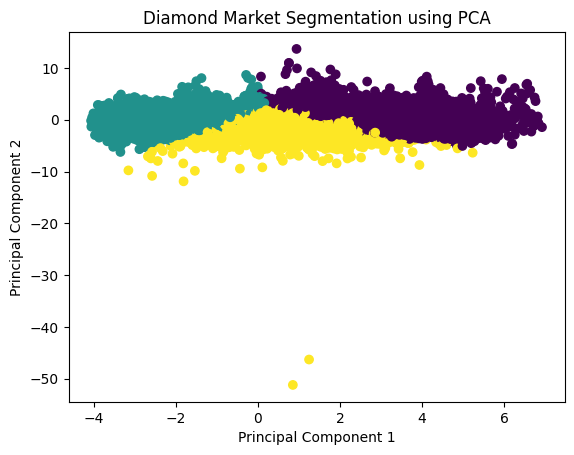

In [15]:
# PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_data = pca.fit_transform(cluster_scaled)

plt.scatter(pca_data[:,0], pca_data[:,1], c=df['cluster'])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Diamond Market Segmentation using PCA")
plt.show()


In [16]:
#CLUSTER NAMING LOGIC (HOW TO JUSTIFY NAMES)
#Step 1: Analyze cluster statistics

cluster_summary = df.groupby('cluster')[['carat','price_inr','volume']].mean()
cluster_summary


,carat,price_inr,volume
cluster,,,
0,1.163310,518111.470592,188.432132
1,0.392484,83837.596477,64.427788
2,0.772218,254603.053518,125.961276


In [17]:
#| Cluster | Carat  | Price  | Interpretation        |
#| ------- | ------ | ------ | --------------------- |
#|Low     | Low    | Low    | Small budget diamonds |
#| Medium  | Medium | Medium | Balanced diamonds     |
#| High    | High   | High   | Premium diamonds      |



cluster_names = {
    0: "Affordable Small Diamonds",
    1: "Mid-range Balanced Diamonds",
    2: "Premium Heavy Diamonds"
}
